# [DEMO] Logical Pauli Product Measurement — BB Gross Code

In [1]:
from contextlib import redirect_stdout
from hashlib import sha256
from io import StringIO
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "lightstim").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from IPython.display import Image, display
from lightstim.protocols.bb_ppm import BBPPMExperiment, BBPPMStep
from lightstim.qec_code.BB_code.ppm import build_tour_de_gross_code
from lightstim.qec_code.BB_code.ppm.reporting import compact_circuit_layout, write_circuit_preview

REFERENCE = ROOT / "benchmarks/logical_ops/reference/bb_ppm/y1_large_20261124"
OUTPUT = ROOT / "benchmarks/logical_ops/results/bb_ppm_code_demo"
OUTPUT.mkdir(parents=True, exist_ok=True)

## 1. Build the PPM Circuit

In [2]:
ppm_sequence = [BBPPMStep(((1, "Y"),))]
gross = build_tour_de_gross_code()
experiment = BBPPMExperiment(
    gross, ppm_sequence, rounds=10, initial_states="X", final_measure_states="X",
)
with redirect_stdout(StringIO()):
    circuit = experiment.build()

print(f"{circuit.num_qubits} physical qubits, {circuit.num_ticks} ticks, "
      f"{circuit.num_detectors} detectors, {circuit.num_observables} observables")

378 physical qubits, 175 ticks, 2300 detectors, 11 observables


## 2. Full Circuit Diagram



Stim circuit: benchmarks/logical_ops/results/bb_ppm_code_demo/full_circuit.stim
Circuit diagram: benchmarks/logical_ops/results/bb_ppm_code_demo/full_circuit.svg


In [3]:
drawing = compact_circuit_layout(circuit.without_noise(), bb_qubits=gross.num_qubits)
svg = str(drawing.diagram("detslice-with-ops-svg", rows=(drawing.num_ticks + 4) // 4))

circuit_path = OUTPUT / "full_circuit.stim"
diagram_path = OUTPUT / "full_circuit.svg"
circuit.to_file(circuit_path)
diagram_path.write_bytes(svg.encode())

preview_path = OUTPUT / "full_circuit.png"
write_circuit_preview(diagram_path, preview_path)
display(Image(filename=str(preview_path), width=1000))

print("Stim circuit:", circuit_path.relative_to(ROOT).as_posix())
print("Circuit diagram:", diagram_path.relative_to(ROOT).as_posix())

## 3. Noiseless Sanity Check

In [4]:
shots = 32
detectors, observables = circuit.without_noise().compile_detector_sampler(seed=0).sample(
    shots=shots, separate_observables=True,
)
print(f"Shots with a detector event: {detectors.any(axis=1).sum()}/{shots}")
print(f"Shots with a logical observable flip: {observables.any(axis=1).sum()}/{shots}")
assert not detectors.any() and not observables.any()

Shots with a detector event: 0/32
Shots with a logical observable flip: 0/32


## 4. Logical Error Rate vs Physical Error Rate

In [5]:
from benchmarks.logical_ops.bb_ppm_runner import available_workers, compiled_plan_sha256, run_campaign
from benchmarks.logical_ops.plot_bb_ppm import create_figure, read_results, result_table

# The bundled results are for Y1. Enable sampling to evaluate another target.
RUN_SAMPLING = False
results_path = REFERENCE / "results.csv"
if RUN_SAMPLING:
    run_dir = OUTPUT / "sampling" / compiled_plan_sha256(experiment.plans)
    results_path = run_dir / "results.csv"
    run_campaign(
        sequence=ppm_sequence, plans=experiment.plans, rounds=experiment.rounds,
        initial_states=experiment.initial_states, final_measure_states=experiment.final_measure_states,
        p_values=(0.0005, 0.001, 0.002), shots=(1_000_000, 1_000_000, 100_000),
        workers=min(32, available_workers()), run_dir=run_dir, output=results_path, seed=2026112404,
    )

results = read_results(
    results_path, expected_plan_sha256=compiled_plan_sha256(experiment.plans),
    expected_experiment={"clean_circuit_sha256": sha256(str(circuit).encode()).hexdigest()},
)
display(result_table(results))

,p,Shots,Failures,LER (95% CI),Nonconverged,Valid & correct,95% one-sided upper bound
0,5 × 10⁻⁴,1000000,4,[0.04 (+0.0624 / −0.0291)] × 10⁻⁴,50,999950,0.09153 × 10⁻⁴
1,1 × 10⁻³,1000000,19,[0.019 (+0.0107 / −0.00756)] × 10⁻³,280,999719,0.02788 × 10⁻³
2,2 × 10⁻³,100000,116,[1.16 (+0.231 / −0.201)] × 10⁻³,313,99674,1.353 × 10⁻³


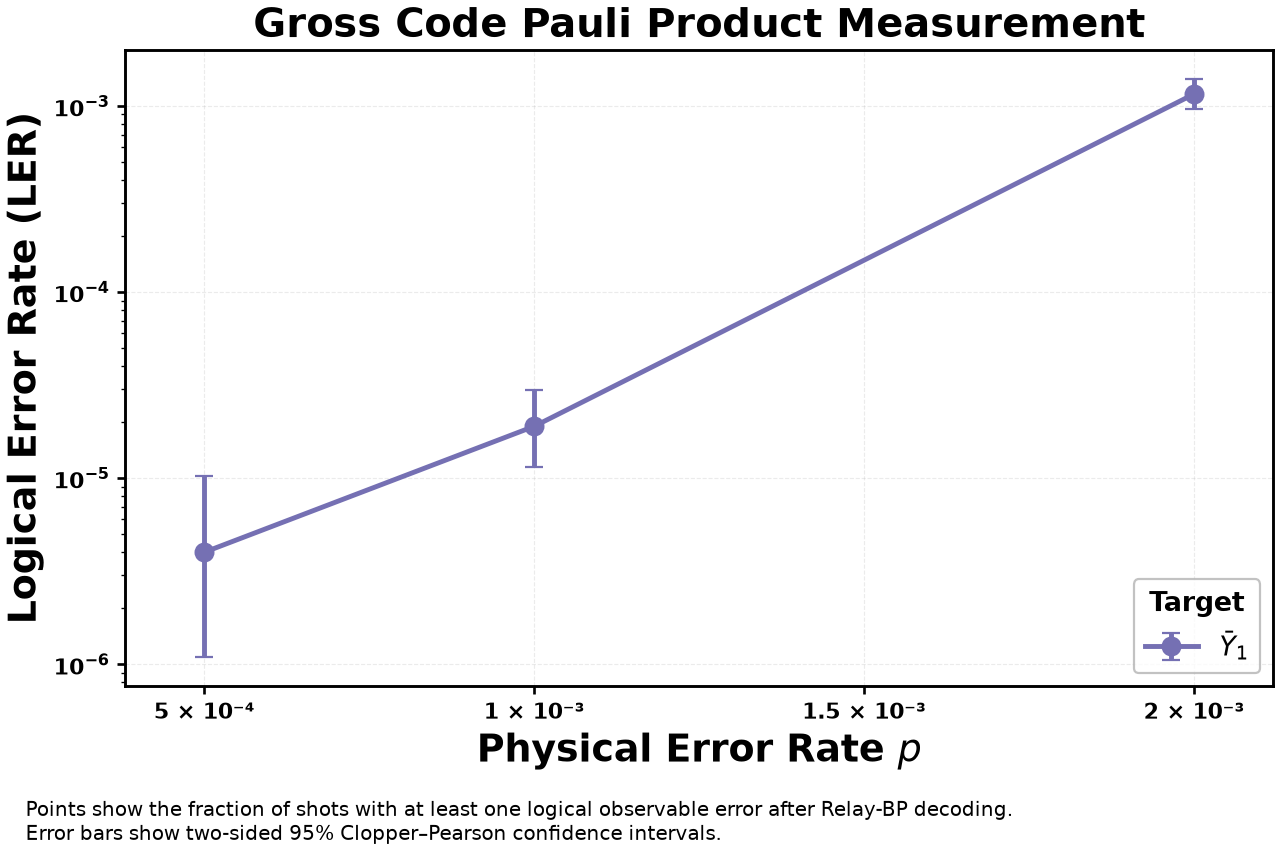

LER figure: benchmarks/logical_ops/results/bb_ppm_code_demo/ler.png


In [6]:
figure_path = OUTPUT / "ler.png"
create_figure(results).savefig(figure_path, dpi=160)
display(Image(filename=str(figure_path), width=800))
print("LER figure:", figure_path.relative_to(ROOT).as_posix())